# 03.7 — Análise de Leakage + Resumo Final
**Depende de:** 03.3 executado antes (artefatos em out/artifacts/)
**Salva em:** out/03.7_leakage/

In [1]:
from __future__ import annotations

import json
import pickle
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "en"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "leakage_xlabel":   "AUROC (Conjunto de Teste)",
        "leakage_title_fmt":"Análise de Leakage — {nome}\nΔAUROC = {delta:+.4f}",
    },
    "en": {
        "leakage_xlabel":   "AUROC (Test Set)",
        "leakage_title_fmt":"Leakage Analysis — {nome}\nΔAUROC = {delta:+.4f}",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.7_leakage"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

## Carregar Artefatos

In [2]:
with open(ART_DIR / "splits.pkl", "rb") as f:
    _splits = pickle.load(f)

df_train      = _splits["df_train"]
df_valid      = _splits["df_valid"]
df_test       = _splits["df_test"]
y_train       = _splits["y_train"]
y_valid       = _splits["y_valid"]
y_test        = _splits["y_test"]
X_train_t     = _splits["X_train_t"]
X_valid_t     = _splits["X_valid_t"]
X_test_t      = _splits["X_test_t"]
X_train       = _splits["X_train"]
X_valid       = _splits["X_valid"]
X_test        = _splits["X_test"]
X_train_all   = _splits["X_train_all"]
X_valid_all   = _splits["X_valid_all"]
X_test_all    = _splits["X_test_all"]
X_train_all_t = _splits["X_train_all_t"]
X_valid_all_t = _splits["X_valid_all_t"]
X_test_all_t  = _splits["X_test_all_t"]

with open(ART_DIR / "features.json", "r", encoding="utf-8") as f:
    _feat = json.load(f)
FEATURES                = _feat["FEATURES"]
FEATURES_ADMISSAO       = _feat["FEATURES_ADMISSAO"]
FEATURES_POS_ATENDIMENTO= _feat["FEATURES_POS_ATENDIMENTO"]
FEATURES_ALL            = _feat["FEATURES_ALL"]
FEATURES_POS_PRESENT    = _feat["FEATURES_POS_PRESENT"]
TARGET_PRINCIPAL        = _feat["TARGET_PRINCIPAL"]
THRESHOLD               = _feat["THRESHOLD"]
TARGETS                 = _feat["TARGETS"]

# _Dummy precisa existir neste escopo antes de unpickle
class _Dummy:
    def __init__(self, prev=0.5):
        self.prev = prev
    def predict_proba(self, X):
        n = len(X) if hasattr(X, "__len__") else X.shape[0]
        return np.column_stack([1 - self.prev * np.ones(n),
                                       self.prev * np.ones(n)])

with open(ART_DIR / "modelos_fit.pkl", "rb") as f:
    modelos_fit = pickle.load(f)

with open(ART_DIR / "probs_teste.pkl", "rb") as f:
    probs_teste = pickle.load(f)

with open(ART_DIR / "thresholds_opt.json", "r", encoding="utf-8") as f:
    threshold_youden_por_modelo = json.load(f)

with open(ART_DIR / "preprocessor.pkl", "rb") as f:
    _preproc_d = pickle.load(f)
preproc = _preproc_d["preproc"]

print(f"Modelos carregados: {list(modelos_fit.keys())}")
print(f"FEATURES: {len(FEATURES)}  FEATURES_ALL: {len(FEATURES_ALL)}")

# ── Flags e helpers ────────────────────────────────────────────────────────
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False


def _predict_proba(nome, clf, X_raw, X_transformed):
    if nome == "M5_CAT" and HAS_CAT:
        return clf.predict_proba(X_raw)[:, 1]
    try:
        return clf.predict_proba(X_transformed)[:, 1]
    except Exception:
        return clf.predict_proba(X_raw)[:, 1]


from sklearn.metrics import roc_auc_score

# Modelo principal para análise
nome_principal = next(n for n in ["M3_XGB","M5_CAT","M4_LGB","M2_RF","M1_LogReg"] if n in modelos_fit)
clf_principal  = modelos_fit[nome_principal]

## 19. Análise de Leakage Potencial (P0)

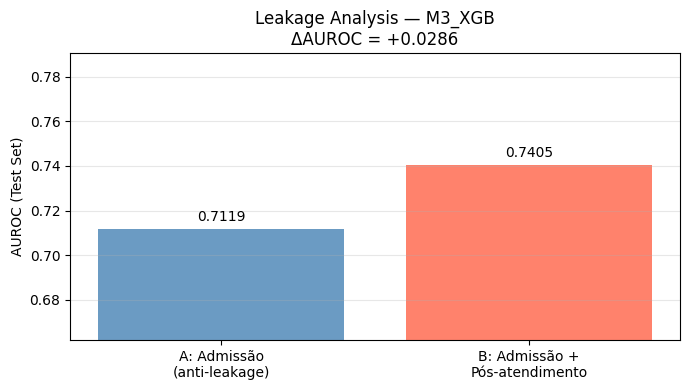

In [3]:
print("\n" + "=" * 70)
print("ANÁLISE DE LEAKAGE POTENCIAL")
print("  Modelo A: FEATURES_ADMISSAO apenas (anti-leakage) — modelo primário")
print("  Modelo B: FEATURES_ADMISSAO + FEATURES_POS_ATENDIMENTO (todas as features)")
print("=" * 70)

# Modelo A já treinado: clf_principal com FEATURES
# Modelo B: treinar com FEATURES_ALL
best_clf_name = next(n for n in ["M3_XGB","M4_LGB","M2_RF","M1_LogReg"] if n in modelos_fit)
best_clf = modelos_fit[best_clf_name]

try:
    if best_clf_name == "M5_CAT" and HAS_CAT:
        try:
            params_b = best_clf.get_params()
        except Exception:
            params_b = {"iterations": 400, "depth": 5, "learning_rate": 0.05,
                         "random_seed": 42, "verbose": 0, "nan_mode": "Min"}
        clf_leakage = CatBoostClassifier(**params_b)
        clf_leakage.fit(X_train_all, y_train, verbose=0)
        prob_leakage_test = clf_leakage.predict_proba(X_test_all)[:, 1]
    else:
        try:
            clf_leakage = best_clf.__class__(**best_clf.get_params())
        except Exception:
            clf_leakage = best_clf.__class__()
        clf_leakage.fit(X_train_all_t, y_train)
        prob_leakage_test = clf_leakage.predict_proba(X_test_all_t)[:, 1]

    auroc_a = roc_auc_score(y_test, _predict_proba(best_clf_name, best_clf, X_test, X_test_t))
    auroc_b = roc_auc_score(y_test, prob_leakage_test)
    delta_auroc = auroc_b - auroc_a

    print(f"\n  Modelo A ({best_clf_name}, FEATURES_ADMISSAO={len(FEATURES)}): AUROC={auroc_a:.4f}")
    print(f"  Modelo B ({best_clf_name}, FEATURES_ALL={len(FEATURES_ALL)}):    AUROC={auroc_b:.4f}")
    print(f"  Delta AUROC (B - A) = {delta_auroc:+.4f}")
    if abs(delta_auroc) > 0.02:
        print(f"  AVISO: delta AUROC > 0.02 sugere que features pós-atendimento adicionam informação!")
        print(f"         Potencial leakage se essas features forem usadas sem cautela em produção.")
    else:
        print(f"  INFO: delta AUROC <= 0.02 — impacto das features pós-atendimento é marginal.")

    leakage_df = pd.DataFrame([
        {"conjunto_features": "ADMISSAO", "n_features": len(FEATURES), "auroc": round(auroc_a, 4)},
        {"conjunto_features": "ADMISSAO+POS_ATENDIMENTO", "n_features": len(FEATURES_ALL), "auroc": round(auroc_b, 4)},
    ])
    leakage_df["delta_auroc"] = [0, round(delta_auroc, 4)]
    leakage_df.to_csv(OUT_DIR / "analise_leakage_potencial.csv", index=False)
    print("  Gerado: analise_leakage_potencial.csv")

    # Gráfico comparativo
    fig_lk, ax_lk = plt.subplots(figsize=(7, 4))
    ax_lk.bar(["A: Admissão\n(anti-leakage)", "B: Admissão +\nPós-atendimento"],
              [auroc_a, auroc_b], color=["steelblue", "tomato"], alpha=0.8)
    ax_lk.set_ylabel(T["leakage_xlabel"])
    ax_lk.set_title(T["leakage_title_fmt"].format(nome=best_clf_name, delta=delta_auroc))
    ax_lk.set_ylim(max(0, min(auroc_a, auroc_b) - 0.05), min(1.0, max(auroc_a, auroc_b) + 0.05))
    ax_lk.grid(axis="y", alpha=0.3)
    for i, (lbl, v) in enumerate(zip(["A", "B"], [auroc_a, auroc_b])):
        ax_lk.text(i, v + 0.002, f"{v:.4f}", ha="center", va="bottom", fontsize=10)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "19_leakage_auroc_comparacao.png", dpi=150)
    plt.show(); plt.close()

except Exception as e:
    print(f"  Erro na análise de leakage: {e}")

## 21. Resumo Final e Export

In [4]:
def seg_cid(c):
    if pd.isna(c): return "Sem CID"
    c = str(c).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10,17)]: return "Hipertensivos"
    if c[:3] == "O24": return "Diabetes Gest."
    if c[:3] in ["O60","O42","O47"]: return "Parto Prematuro"
    if c[0]=="O" and c[1] in "234": return "Hemorragia"
    if c[:3]=="O98": return "Infecção"
    if c[:3]=="O99": return "Comorbidades"
    if c[0]=="P": return "Risco Neonatal"
    if c[0]=="O": return "Outros Obstétricos"
    if c[:2]=="Z3": return "Pré-natal"
    return "Outros"

df_test["segmento"] = df_test["cd_cid"].apply(seg_cid)

In [5]:
df_test_out = df_test[["cd_atendimento", "cd_paciente", "dt_atendimento",
                         "segmento", "y_retorno_30d", "y_retorno_90d",
                         "y_obito_materno", "y_desfecho_grave"]].copy()
df_test_out["prob_retorno_30d"] = _predict_proba(nome_principal, clf_principal, X_test, X_test_t)
df_test_out.to_parquet(OUT_DIR / "test_predictions.parquet", index=False)

# Listar todos os outputs gerados nas etapas anteriores
all_out_dirs = [
    ROOT / "out" / "03.1_preparacao",
    ROOT / "out" / "03.2_treinamento",
    ROOT / "out" / "03.3_calibracao",
    ROOT / "out" / "03.4_xai",
    ROOT / "out" / "03.5_equidade",
    ROOT / "out" / "03.6_inferencia",
    ROOT / "out" / "03.7_leakage",
]

all_outputs = []
for d in all_out_dirs:
    if d.exists():
        for p in sorted(d.rglob("*")):
            if p.is_file():
                all_outputs.append(str(p.relative_to(ROOT / "out")))

resumo = {
    "data_execucao"   : datetime.now().isoformat(),
    "n_treino"        : int(len(df_train)),
    "n_valid"         : int(len(df_valid)),
    "n_teste"         : int(len(df_test)),
    "n_features_admissao" : len(FEATURES),
    "n_features_all"  : len(FEATURES_ALL),
    "features_admissao": FEATURES,
    "features_pos_atendimento": FEATURES_POS_PRESENT,
    "modelos"         : list(modelos_fit.keys()),
    "target_principal": TARGET_PRINCIPAL,
    "threshold_fixo"  : 0.30,
    "threshold_youden_por_modelo": threshold_youden_por_modelo,
    "outputs"         : all_outputs,
}
(OUT_DIR / "resumo.json").write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"""
╔══════════════════════════════════════════════════════════════════════╗
║  Modelos Clássicos — Concluído (TRIPOD+AI)                          ║
╠══════════════════════════════════════════════════════════════════════╣
║  [P0] ANTI-LEAKAGE                                                  ║
║   FEATURES_ADMISSAO: {len(FEATURES):<4} features — modelo primário           ║
║   FEATURES_ALL:      {len(FEATURES_ALL):<4} features — análise de leakage         ║
║   analise_leakage_potencial.csv                                     ║
╠══════════════════════════════════════════════════════════════════════╣
║  CSVs para o Paper:                                                 ║
║   tabela1_baseline.csv          (Table 1 — TRIPOD)                  ║
║   missing_data_por_split.csv    (dados faltantes)                   ║
║   tabela_modelos_teste.csv      (métricas + NPV/MCC/F1/Youden)     ║
║   calibration_slope_intercept.csv                                   ║
║   nri_idi_vs_logreg.csv         (NRI/IDI)                           ║
║   fairness_faixa_etaria.csv     (equidade demográfica)              ║
║   fairness_por_ano.csv          (drift temporal)                    ║
║   fairness_tipo_atendimento.csv (tipo de atendimento)               ║
║   fairness_paridade.csv         (primigesta/secundigesta/multipara) ║
║   tabela_todos_modelos_todos_targets.csv                            ║
║   subgrupo_cid_teste.csv        (subgrupos CID)                     ║
║   odds_ratios_logit.csv         (OR para paper)                     ║
║   nne_por_target.csv            (NNE/utilidade clínica)             ║
║   testes_hosmer_lemeshow_calibrado.csv                              ║
║   testes_delong.csv / testes_mcnemar.csv                            ║
║   shap_importancia_global_todos_modelos.csv                         ║
║   learning_curve_data.csv                                           ║
║   drift_temporal_auroc_por_ano.csv                                  ║
║   test_predictions.parquet                                          ║
╠══════════════════════════════════════════════════════════════════════╣
║  Plots:                                                             ║
║   01  ROC + PR curves                                               ║
║   02  Calibração (bins)                                             ║
║   02b Calibração antes vs depois (Platt/Isotonic)                  ║
║   02c Calibração suavizada (LOWESS)                                 ║
║   03  SHAP Summary (por modelo)                                     ║
║   04  SHAP Importância Global (por modelo)                          ║
║   05  Subgrupo CID AUROC                                            ║
║   05b Fairness Faixa Etária                                         ║
║   05c Fairness por Ano (drift)                                      ║
║   05d Fairness por Tipo Atendimento                                 ║
║   05e Fairness por Paridade                                         ║
║   06  Threshold Analysis (0.30 + Youden)                            ║
║   07  Forest Plot OR                                                ║
║   08  SHAP Waterfall Alto Risco                                     ║
║   09  SHAP Waterfall Baixo Risco                                    ║
║   10  SHAP Dependence                                               ║
║   11a DCA Todos os Modelos (calibrados)                             ║
║   11b DCA Multi-Target                                              ║
║   15  Drift Temporal AUROC por Ano                                  ║
║   19  Leakage AUROC comparação                                      ║
║   learning_curve.png                                                ║
╚══════════════════════════════════════════════════════════════════════╝
""")

print(f"\n[03.7] Concluído. Outputs: {OUT_DIR}")